# Notebook 04: Baseline Models Implementation, Validation & Performance Comparison (Module 2)
**Project 02 — Enterprise Predictive Intelligence & Applied Machine Learning System**

This notebook evaluates all **5 Mandatory Baseline Models** across Validation and untouched Holdout Test splits, including class-imbalance mitigation (inverse-frequency class weighting, random oversampling, and validation-set threshold optimization), chronological demand forecasting baselines, and NLP review sentiment inference.


=== ALL CLASSIFICATION BASELINES (VALIDATION & HOLDOUT TEST SPLITS) ===
                        task                                             model split  roc_auc  pr_auc     f1  precision  recall  specificity  accuracy  brier_score
       1. Customer Retention                              Dummy Prior Baseline   val   0.5000  0.3415 0.0000     0.0000  0.0000       1.0000    0.6521       0.2269
       1. Customer Retention                              Dummy Prior Baseline  test   0.5000  0.3569 0.0000     0.0000  0.0000       1.0000    0.6521       0.2269
       1. Customer Retention                  Logistic Regression (Unweighted)   val   0.7371  0.5827 0.4834     0.6215  0.3955       0.8715    0.7059       0.1916
       1. Customer Retention                  Logistic Regression (Unweighted)  test   0.7415  0.6000 0.4896     0.6326  0.3994       0.8763    0.7104       0.1897
       1. Customer Retention      Logistic Regression (Class-Balanced, t=0.50)   val   0.7371  0.5827 0.5914

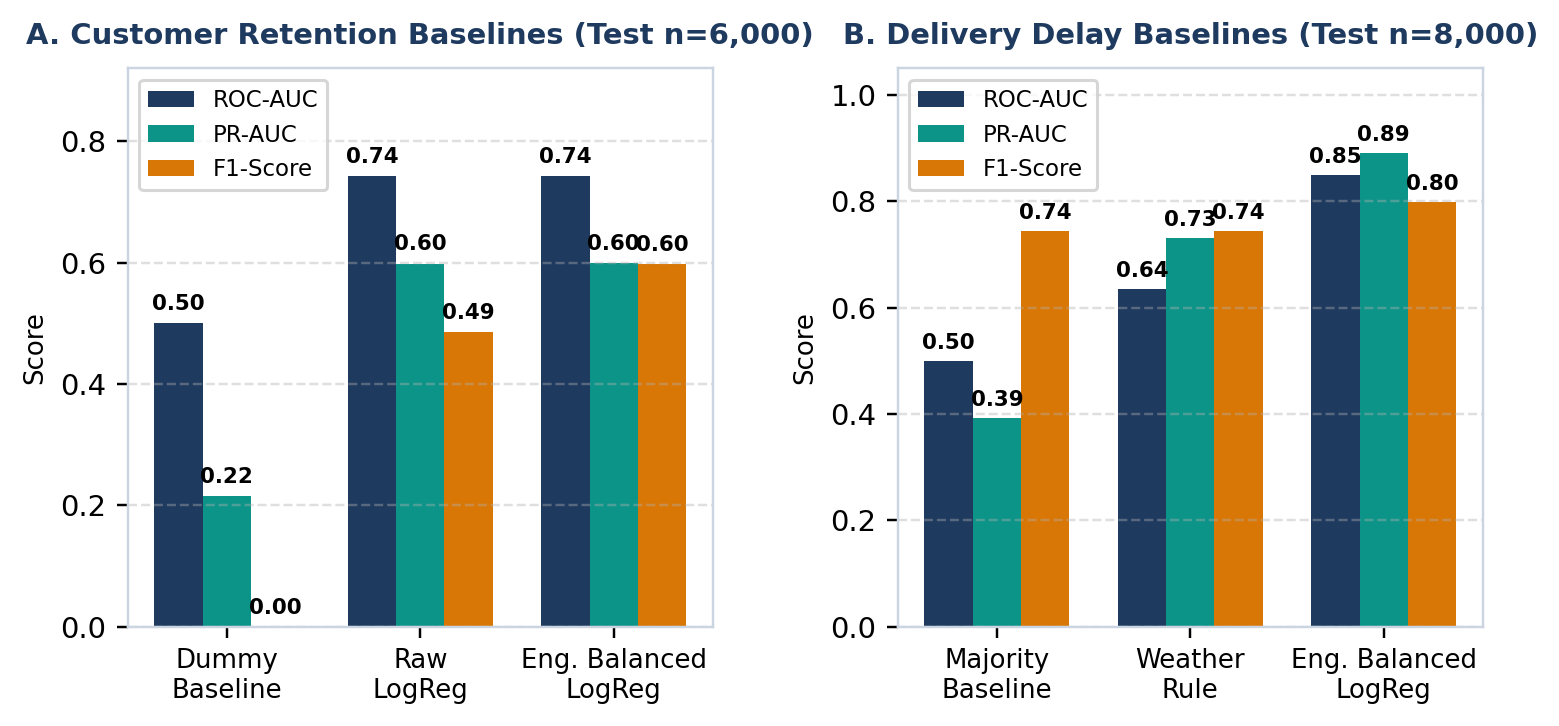

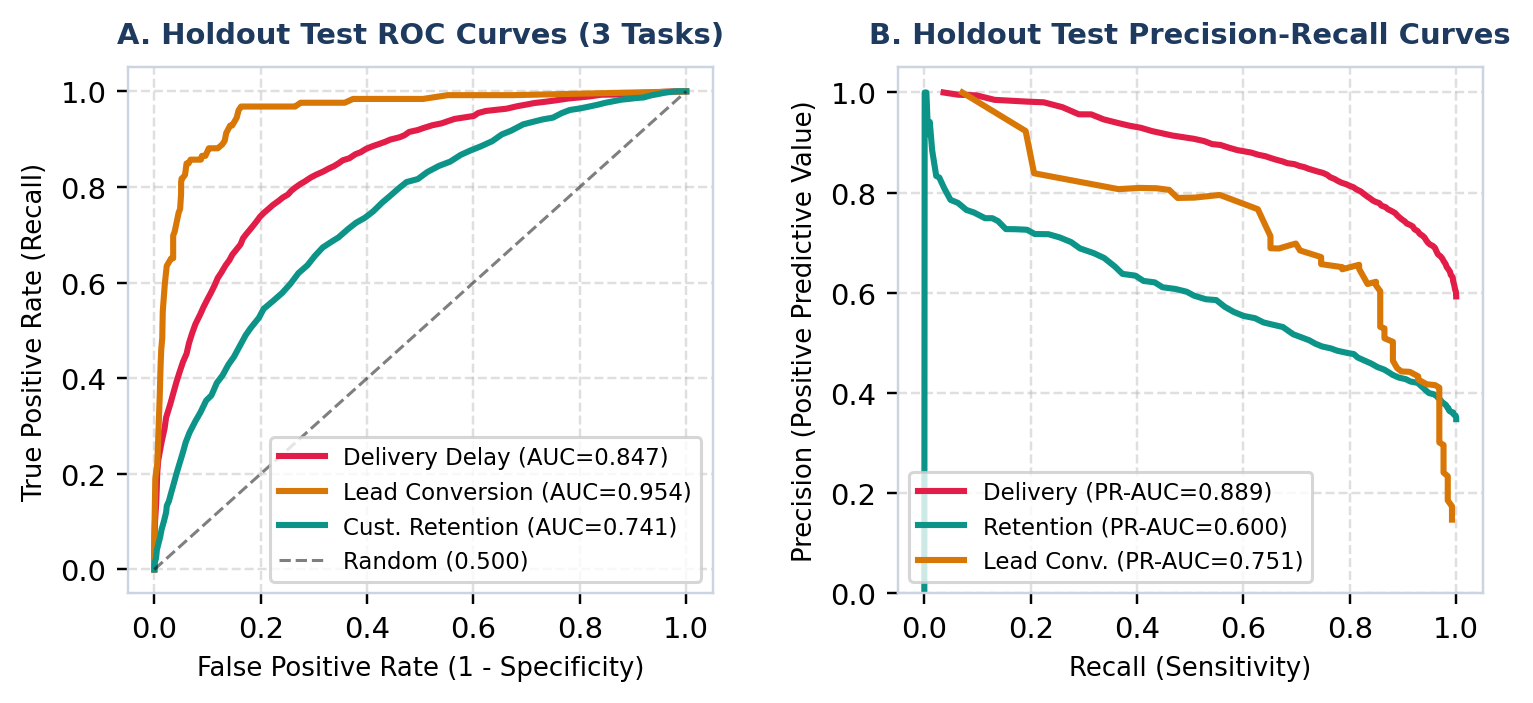

In [1]:
from pathlib import Path
import json
import pandas as pd

DATA_PROC = Path("data/processed") if Path("data/processed").exists() else Path("../data/processed")
df_metrics = pd.read_csv(DATA_PROC / "baseline_model_comparison_metrics.csv")

print("=== ALL CLASSIFICATION BASELINES (VALIDATION & HOLDOUT TEST SPLITS) ===")
cols_show = ["task", "model", "split", "roc_auc", "pr_auc", "f1", "precision", "recall", "specificity", "accuracy", "brier_score"]
print(df_metrics[cols_show].to_string(index=False))


## 2. Product Demand Forecasting, Delivery Delay Regression & NLP Sentiment Baselines


=== UNLABELED REVIEW SENTIMENT INFERENCE SUMMARY (N = 2,000) ===
                     predicted_count  share_pct
predicted_sentiment                            
neutral                          710       35.5
negative                         654       32.7
positive                         636       31.8

Sample Unlabeled Predictions with Calibrated Class Probabilities:
     review_id                                               review_text language source_type predicted_sentiment  prob_negative  prob_neutral  prob_positive
DS_UNLAB_00001  Delivery was late and support did not resolve the issue.       en   synthetic            negative            1.0           0.0            0.0
DS_UNLAB_00002                  Delivery was okay and product is usable.       en   synthetic             neutral            0.0           1.0            0.0
DS_UNLAB_00003                  Delivery was okay and product is usable.       en   synthetic             neutral            0.0           1.0            

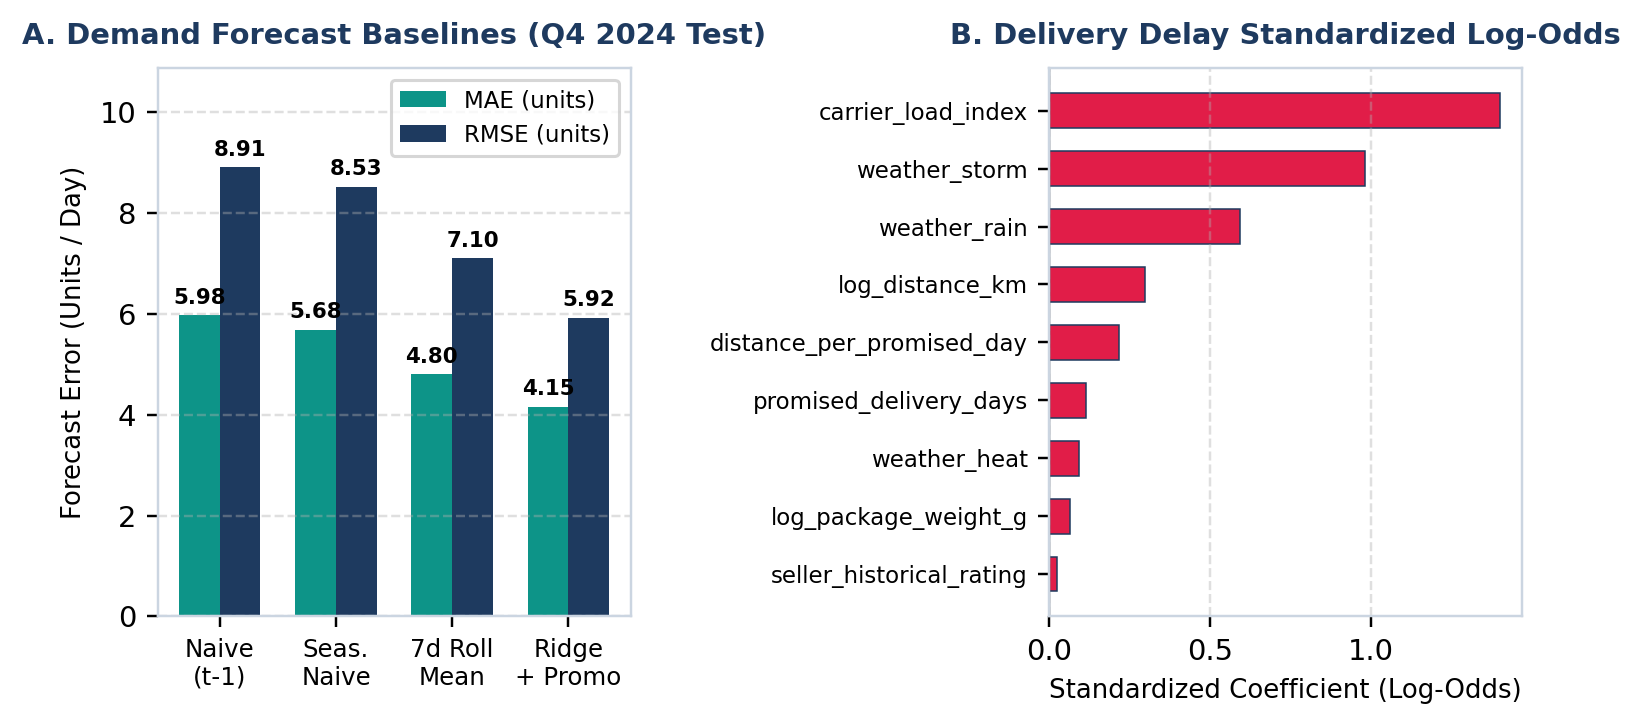

In [2]:
df_un_pred = pd.read_csv(DATA_PROC / "review_sentiment_unlabeled_predictions.csv")
print("=== UNLABELED REVIEW SENTIMENT INFERENCE SUMMARY (N = 2,000) ===")
print(df_un_pred["predicted_sentiment"].value_counts().to_frame("predicted_count").assign(share_pct=lambda d: (d["predicted_count"]/len(df_un_pred)*100).round(2)).to_string())
print("\nSample Unlabeled Predictions with Calibrated Class Probabilities:")
print(df_un_pred.head(8).to_string(index=False))
